In [3]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import zipfile
import io
import warnings
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import(classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score)
from google.colab import drive

warnings.filterwarnings("default")
seed = 42
image_size = (128, 128)
epochs = 20
zip_path = Path("PetImages.zip")
extract_dir = Path("PetImages_data")
batch_size = 120
validation_split = 0.20

# set a random tf and np seed
np.random.seed(seed)
tf.random.set_seed(seed)
print(f"Tensorflow version available: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

Tensorflow version available: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [2]:
def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, image_size)
    image = tf.cast(image, tf.float32)/255
    label = tf.cast(label, tf.int32)
    return image, label

In [4]:
drive.mount("/content/drive")
zip_path = Path("/content/drive/MyDrive/PetImages.zip")
extract_dir = Path("/content/PetImages_data")
print("ZIP file exists:", zip_path.exists())


if not zip_path.exists():
    raise FileNotFoundError(
        f"Could not find: {zip_path.resolve()}. "
        "Please add your PetImages.zip in the same folder as this notebook"
    )

if not extract_dir.exists():
    print("Extract PetImages.zip.....")
    with zipfile.ZipFile(zip_path, "r") as zip_file:
        zip_file.extractall(extract_dir)
    print(f"Your dataset as been extracted.")
else:
    print("Your dataset has been extracted")

Mounted at /content/drive
ZIP file exists: True
Extract PetImages.zip.....
Your dataset as been extracted.


In [5]:
def find_dataset_folders(root, folder_name):
    for path in root.rglob("*"):
        if path.is_dir() and path.name.lower() == folder_name.lower():
            children = {child.name.lower() for child in path.iterdir() if child.is_dir()}
            if {"cat", "dog"}.issubset(children):
                return path
    raise FileNotFoundError(
            f"Could not find a {folder_name} folder containing CAT and DOG folders.")

dataset_dir = find_dataset_folders(extract_dir, "PetImages")

print("Dataset directory:", dataset_dir)
print("Cat directory:", dataset_dir / "Cat")
print("Dog directory:", dataset_dir / "Dog")

Dataset directory: /content/PetImages_data/PetImages
Cat directory: /content/PetImages_data/PetImages/Cat
Dog directory: /content/PetImages_data/PetImages/Dog


In [7]:
cat_dir = dataset_dir/"Cat"
dog_dir = dataset_dir/"Dog"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}

cat_images = [
    path for path in cat_dir.iterdir()
    if path.is_file() and path.suffix.lower() in image_extensions
]

dog_images = [
    path for path in dog_dir.iterdir()
    if path.is_file() and path.suffix.lower() in image_extensions
]

image_paths = cat_images + dog_images
labels = [0] * len(cat_images) + [1] * len(dog_images)
assert len(image_paths) == len(labels)

print(f"Number of cats: {len(cat_images)}")
print(f"Number of dogs: {len(dog_images)}")
print(f"Total images: {len(image_paths)}")

Number of cats: 12502
Number of dogs: 12500
Total images: 25002


In [8]:
def is_valid_image(image_path):
    try:
        image = Image.open(image_path)
        image.verify()
        return True
    except Exception:
        return False

from random import randint
cat_number = randint(1, 12000)
dog_number = randint(1, 12000)

print(cat_number)
print(dog_number)
print(is_valid_image(cat_images[cat_number]))
print(is_valid_image(dog_images[dog_number]))

500
1048
True
True


In [10]:
valid_image_paths = []
valid_labels = []

for index, image_path in enumerate(image_paths):
    if is_valid_image(image_path):
        valid_image_paths.append(image_path)
        valid_labels.append(labels[index])

def inspect_class_distribution(valid_labels):
    num_cats = int(valid_labels.count(0))
    num_dogs = int(valid_labels.count(1))
    print(f"Number of cats: {num_cats}")
    print(f"Number of dogs: {num_dogs}")
    print(f"Total Number of cats and dogs: {num_cats + num_dogs}")
    print(f"Percentage of dogs: {num_dogs/(num_cats + num_dogs) * 100}%")
    print(f"Percentage of cats: {num_cats/(num_cats + num_dogs) * 100}%")
inspect_class_distribution(valid_labels)

Number of cats: 12501
Number of dogs: 12499
Total Number of cats and dogs: 25000
Percentage of dogs: 49.996%
Percentage of cats: 50.004000000000005%


In [11]:
def split_dataset(valid_image_paths, valid_labels, seed = 42):
    x_train, x_temp, y_train, y_temp = train_test_split(
        valid_image_paths,
        valid_labels,
        test_size=0.03,
        random_state=seed,
        stratify=valid_labels)

    x_val, x_test, y_val, y_test = train_test_split(
        x_temp,
        y_temp,
        test_size=0.50,
        random_state=seed,
        stratify=y_temp)
    return x_train, x_val, x_test, y_train, y_val, y_test

In [12]:
class_names = ["cats", "dogs"]
x_train, x_val, x_test, y_train, y_val, y_test = split_dataset(valid_image_paths, valid_labels, seed=seed)

def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, image_size)
    image = tf.cast(image, tf.float32)/255
    label = tf.cast(label, tf.int32)
    return image, label

def create_dataset(image_paths, labels, training = False):
    image_paths = tf.constant([str(path) for path in image_paths])
    labels = tf.constant(labels, dtype=tf.int32)
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))
    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(image_paths), 10000),
            seed=seed,
            reshuffle_each_iteration=True)
    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(
        batch_size,
        drop_remainder=False)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [13]:
train_ds = create_dataset(x_train, y_train, training=True)
valid_ds = create_dataset(x_val, y_val)
test_ds = create_dataset(x_test, y_test)

for images, labels in train_ds.take(1):
    print("Training image batch shape:", images.shape)
    print("Training label batch shape:", labels.shape)
for images, labels in valid_ds.take(1):
    print("Validation image batch shape:", images.shape)
    print("Validation label batch shape:", labels.shape)
for images, labels in test_ds.take(1):
    print("Testing image batch shape:", images.shape)
    print("Testing label batch shape:", labels.shape)

def inspect_split_distribution(labels, split_name):
    labels = np.asanyarray(labels)
    num_cats = np.sum(labels == 0)
    num_dogs = np.sum(labels == 1)
    total_images = len(labels)

    print(f"\n{split_name} Dataset")
    print("-" * 35)
    print(f"Cat images: {num_cats}")
    print(f"Dog images: {num_dogs}")
    print(f"Total images: {total_images}")
    if total_images > 0:
        print(f"Cat percentage: {num_cats / total_images * 100:.2f}%")
        print(f"Dog percentage: {num_dogs / total_images * 100:.2f}%")

inspect_split_distribution(y_train, "Training")
inspect_split_distribution(y_val, "Validation")
inspect_split_distribution(y_test, "Testing")

/usr/local/lib/python3.13/dist-packages/gast/astn.py:23: DeprecationWarning: Attribute.__init__ got an unexpected keyword argument '___pyct_anno'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  new_node = cls(
/usr/local/lib/python3.13/dist-packages/gast/astn.py:23: DeprecationWarning: Call.__init__ got an unexpected keyword argument '___pyct_anno'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  new_node = cls(
/usr/local/lib/python3.13/dist-packages/gast/astn.py:23: DeprecationWarning: Constant.__init__ got an unexpected keyword argument '___pyct_anno'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  new_node = cls(
/usr/local/lib/python3.13/dist-packages/gast/astn.py:23: DeprecationWarning: keyword.__init__ got an unexpected keyword argument '___pyct_anno'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  new_

Training image batch shape: (120, 128, 128, 3)
Training label batch shape: (120,)
Validation image batch shape: (120, 128, 128, 3)
Validation label batch shape: (120,)
Testing image batch shape: (120, 128, 128, 3)
Testing label batch shape: (120,)

Training Dataset
-----------------------------------
Cat images: 12126
Dog images: 12124
Total images: 24250
Cat percentage: 50.00%
Dog percentage: 50.00%

Validation Dataset
-----------------------------------
Cat images: 187
Dog images: 188
Total images: 375
Cat percentage: 49.87%
Dog percentage: 50.13%

Testing Dataset
-----------------------------------
Cat images: 188
Dog images: 187
Total images: 375
Cat percentage: 50.13%
Dog percentage: 49.87%


In [14]:
data_argumentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomTranslation(width_factor=0.05, height_factor=0.05, fill_mode="reflect")],
    name = "data_argumentation")

inputs = tf.keras.Input(shape=(128, 128, 3), name="Input_image")
x = data_argumentation(inputs)
x = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
x = tf.keras.layers.MaxPool2D()(x)
x = tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
x = tf.keras.layers.MaxPool2D()(x)
x = tf.keras.layers.Conv2D(258, 3, padding="same", activation="relu")(x)
x = tf.keras.layers.MaxPool2D()(x)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
x = tf.keras.layers.Dense(1, activation="sigmoid", name = "cat_vs_dog_probability")(x)
model = tf.keras.Model(inputs = inputs, outputs = x, name = "cat_vs_dog_classifier")
model.summary()

Model: "cat_vs_dog_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_image (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_argumentation (Sequential) │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 258)    │       297,474 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 258)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 258)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 258)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cat_vs_dog_probability (Dense)  │ (None, 1)              │           259 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 373,381 (1.42 MB)

 Trainable params: 373,381 (1.42 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
def load_and_preprocess_image(image_path, label):

    # Read the image file as a byte string.
    image_bytes = tf.io.read_file(image_path)

    # Convert the file contents into a NumPy RGB image using Pillow.
    def decode_with_pillow(image_bytes):
        image_bytes = image_bytes.numpy()

        with Image.open(io.BytesIO(image_bytes)) as image:
            image = image.convert("RGB")
            image = image.resize(
                (image_size[1], image_size[0]),
                Image.Resampling.BILINEAR
            )
            image_array = np.asarray(image, dtype=np.float32)

        return image_array / 255.0
    image = tf.py_function(
        func=decode_with_pillow,
        inp=[image_bytes],
        Tout=tf.float32)
    image.set_shape([image_size[0], image_size[1], 3])
    label = tf.cast(label, tf.int32)
    return image, label

# Re-apply maps to train, validation, and test datasets with the updated robust decoder
train_ds = create_dataset(x_train, y_train, training=True)
valid_ds = create_dataset(x_val, y_val)
test_ds = create_dataset(x_test, y_test)

/usr/local/lib/python3.13/dist-packages/gast/astn.py:23: DeprecationWarning: Subscript.__init__ got an unexpected keyword argument '___pyct_anno'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  new_node = cls(
/usr/local/lib/python3.13/dist-packages/gast/astn.py:23: DeprecationWarning: With.__init__ got an unexpected keyword argument '___pyct_anno'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  new_node = cls(


In [17]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.AUC(name="auc")])

# Stop training when validation loss stops improving.
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1)

# Train the model.
history = model.fit(train_ds,
    validation_data=valid_ds,
    epochs=epochs,
    callbacks=[early_stopping],
    verbose=1)

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/core.py:171: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  return np.array(x)


191/203 ━━━━━━━━━━━━━━━━━━━━ 4s 400ms/step - accuracy: 0.5455 - auc: 0.5720 - loss: 0.6809 - precision: 0.5471

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))
<sys>:0: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x7b1e14d02f20>


203/203 ━━━━━━━━━━━━━━━━━━━━ 94s 408ms/step - accuracy: 0.5750 - auc: 0.6123 - loss: 0.6702 - precision: 0.5784 - val_accuracy: 0.6053 - val_auc: 0.6642 - val_loss: 0.6413 - val_precision: 0.6205
Epoch 2/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 83s 407ms/step - accuracy: 0.6336 - auc: 0.6897 - loss: 0.6345 - precision: 0.6500 - val_accuracy: 0.6827 - val_auc: 0.7454 - val_loss: 0.6096 - val_precision: 0.6906
Epoch 3/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 83s 407ms/step - accuracy: 0.6712 - auc: 0.7348 - loss: 0.6033 - precision: 0.6908 - val_accuracy: 0.6933 - val_auc: 0.7868 - val_loss: 0.5668 - val_precision: 0.7296
Epoch 4/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 145s 422ms/step - accuracy: 0.7017 - auc: 0.7685 - loss: 0.5760 - precision: 0.7220 - val_accuracy: 0.6853 - val_auc: 0.7990 - val_loss: 0.6009 - val_precision: 0.6287
Epoch 5/20
203/203 ━━━━━━━━━━━━━━━━━━━━ 83s 407ms/step - accuracy: 0.7155 - auc: 0.7895 - loss: 0.5555 - precision: 0.7335 - val_accuracy: 0.7067 - val_auc: 0.8125 - val_loss: 0.5880

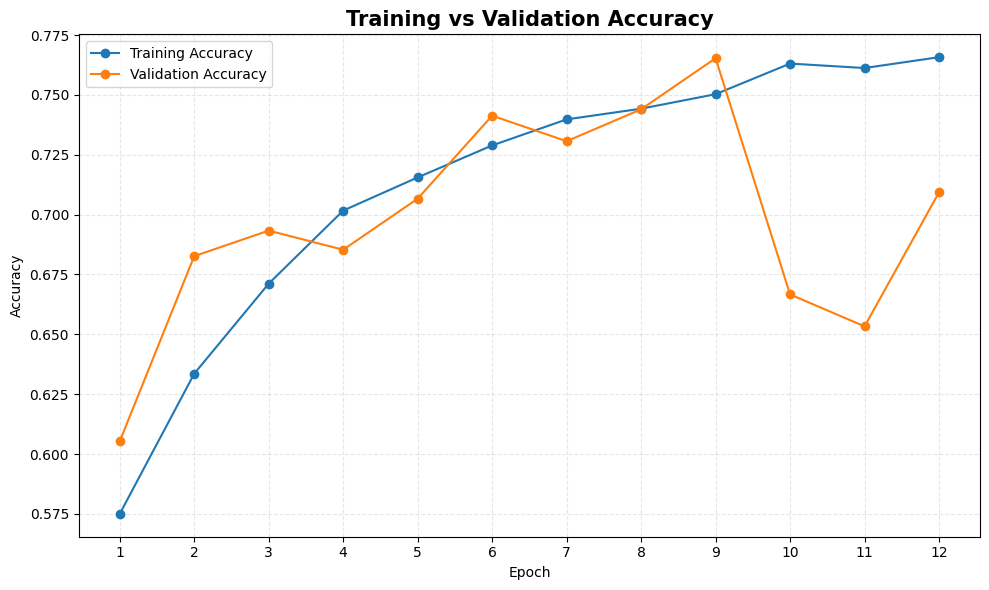

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


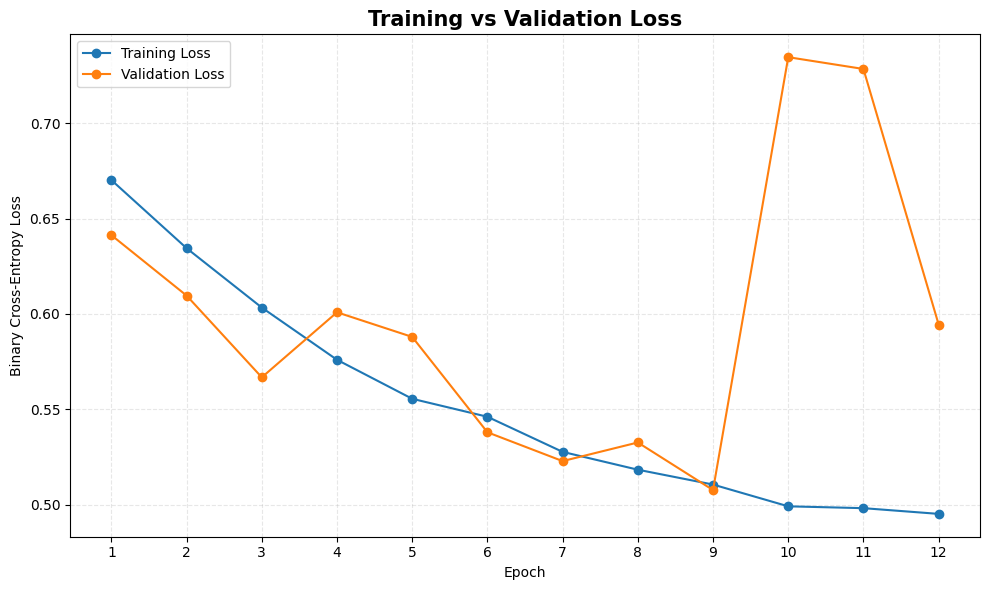

In [18]:
def plot_training_history(history):
    history_data = history.history

    accuracy_key = next((key for key in ["accuracy", "binary_accuracy"]
                         if key in history_data), None)

    # Identify the corresponding validation metric.
    val_accuracy_key = (f"val_{accuracy_key}"
        if accuracy_key is not None
        else None)

    # Plot accuracy if the metrics are available.
    if ( accuracy_key is not None and val_accuracy_key in history_data):
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.plot(
            history_data[accuracy_key],
            label="Training Accuracy",
            marker="o")
        ax.plot(
            history_data[val_accuracy_key],
            label="Validation Accuracy",
            marker="o")

        ax.set_title(
            "Training vs Validation Accuracy",
            fontsize=15,
            fontweight="bold")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy")
        ax.legend()
        ax.grid(True, linestyle="--", alpha=0.3)
        ax.set_xticks(np.arange(len(history_data[accuracy_key])))
        ax.set_xticklabels(np.arange(1, len(history_data[accuracy_key]) + 1))
        plt.tight_layout()
        plt.show()
    # Plot loss.
    if ("loss" in history_data and "val_loss" in history_data):
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.plot(history_data["loss"],
            label="Training Loss",
            marker="o")

        ax.plot(
            history_data["val_loss"],
            label="Validation Loss",
            marker="o")

        ax.set_title(
            "Training vs Validation Loss",
            fontsize=15,
            fontweight="bold")

        ax.set_xlabel("Epoch")
        ax.set_ylabel("Binary Cross-Entropy Loss")
        ax.legend()
        ax.grid(True, linestyle="--", alpha=0.3)
        ax.set_xticks(
            np.arange(len(history_data["loss"])))
        ax.set_xticklabels(
            np.arange(1, len(history_data["loss"]) + 1))
        plt.tight_layout()
        plt.show()
plot_training_history(history)


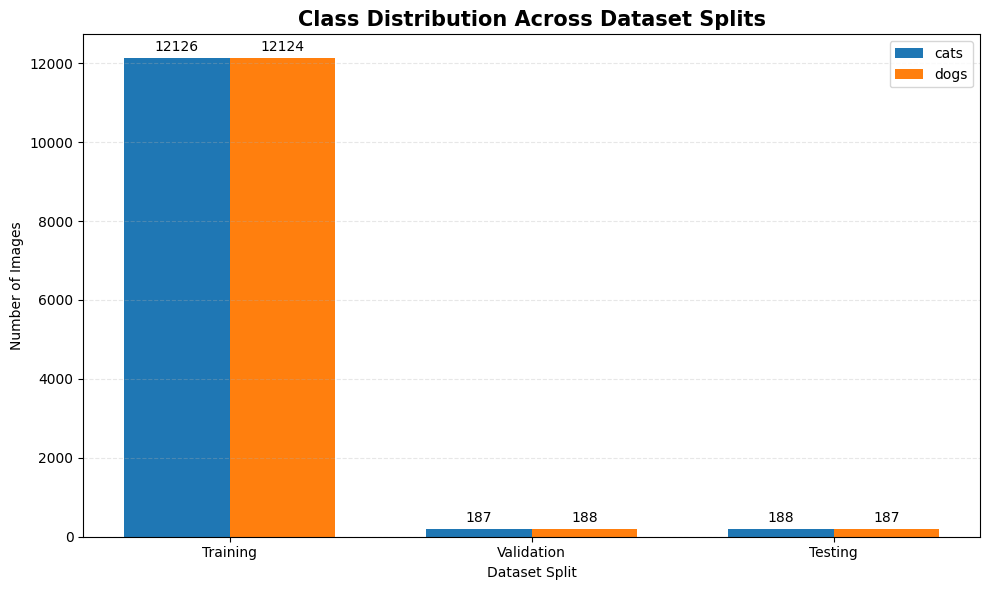

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [19]:
def plot_class_distribution(y_train, y_val, y_test, class_names):

    splits = {
        "Training": np.asarray(y_train),
        "Validation": np.asarray(y_val),
        "Testing": np.asarray(y_test)}

    cat_counts = []
    dog_counts = []

    for labels in splits.values():
        cat_counts.append(np.sum(labels == 0))
        dog_counts.append(np.sum(labels == 1))

    # Set the positions of the bars.
    positions = np.arange(len(splits))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 6))

    # Plot the class counts.
    bars_cat = ax.bar(
        positions - width / 2,
        cat_counts,
        width,
        label=class_names[0])

    bars_dog = ax.bar(
        positions + width / 2,
        dog_counts,
        width,
        label=class_names[1])

    # Add labels and formatting.
    ax.set_title(
        "Class Distribution Across Dataset Splits",
        fontsize=15,
        fontweight="bold")

    ax.set_xlabel("Dataset Split")
    ax.set_ylabel("Number of Images")

    ax.set_xticks(positions)
    ax.set_xticklabels(list(splits.keys()))

    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    # Display the counts above the bars.
    ax.bar_label(bars_cat, padding=3)
    ax.bar_label(bars_dog, padding=3)

    plt.tight_layout()
    plt.show()

plot_class_distribution(y_train, y_val, y_test, class_names)

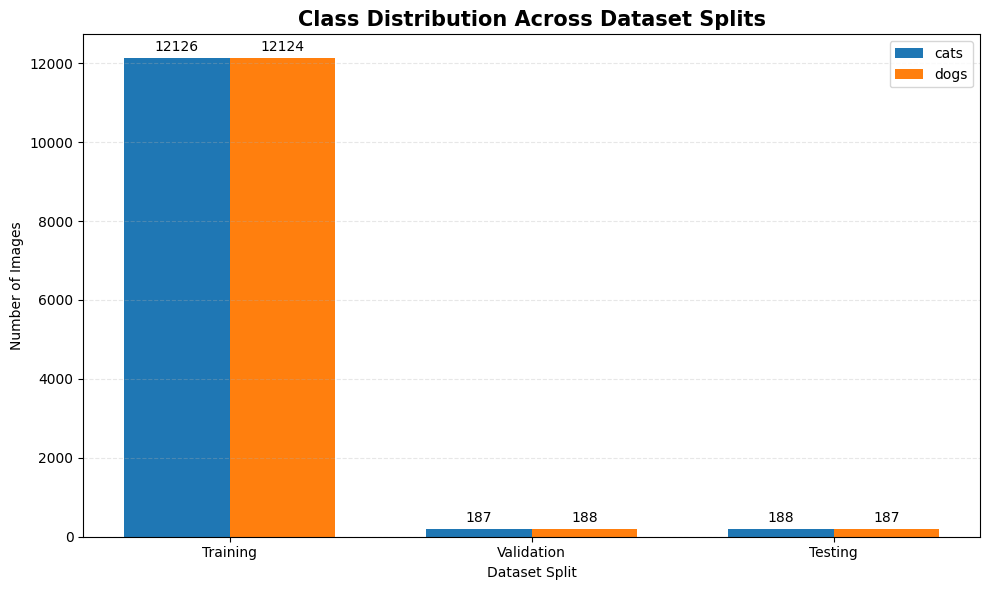

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [20]:
def plot_class_distribution(y_train, y_val, y_test, class_names):
    splits = {
        "Training": np.asarray(y_train),
        "Validation": np.asarray(y_val),
        "Testing": np.asarray(y_test)
    }

    cat_counts = []
    dog_counts = []

    for labels in splits.values():
        cat_counts.append(np.sum(labels == 0))
        dog_counts.append(np.sum(labels == 1))

    # Set the positions of the bars.
    positions = np.arange(len(splits))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 6))

    # Plot the class counts.
    bars_cat = ax.bar(
        positions - width / 2,
        cat_counts,
        width,
        label=class_names[0]
    )

    bars_dog = ax.bar(
        positions + width / 2,
        dog_counts,
        width,
        label=class_names[1]
    )

    # Add labels and formatting.
    ax.set_title(
        "Class Distribution Across Dataset Splits",
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel("Dataset Split")
    ax.set_ylabel("Number of Images")

    ax.set_xticks(positions)
    ax.set_xticklabels(list(splits.keys()))

    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    # Display the counts above the bars.
    ax.bar_label(bars_cat, padding=3)
    ax.bar_label(bars_dog, padding=3)

    plt.tight_layout()
    plt.show()

plot_class_distribution(y_train, y_val, y_test, class_names)

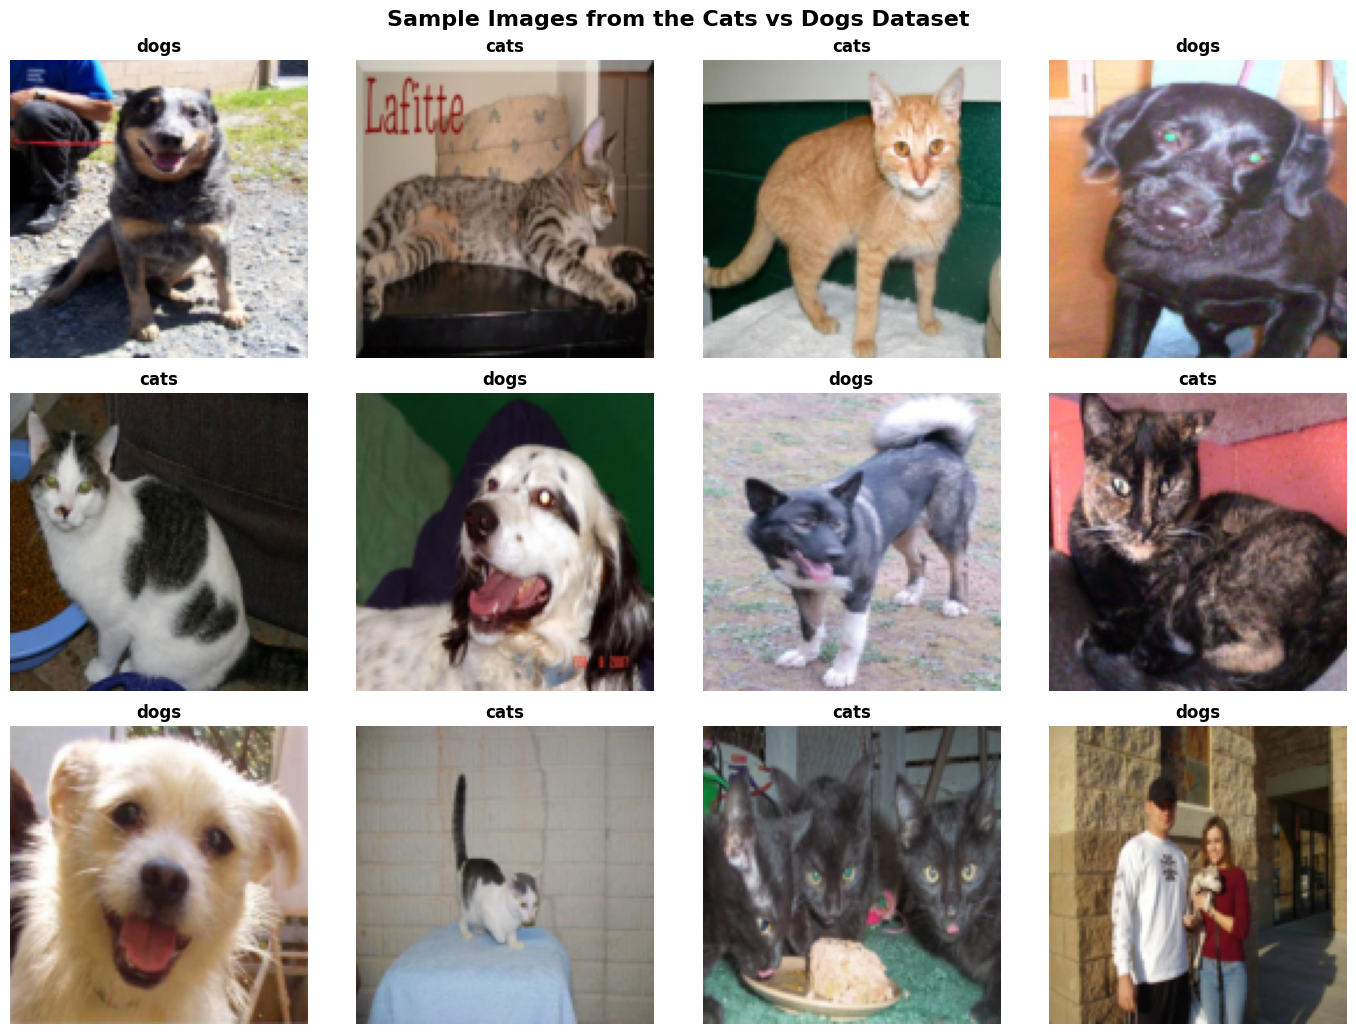

In [21]:
def plot_predictions(model, dataset, class_names, num_images=12):

    # Retrieve a batch from the dataset.
    for images, labels in dataset.take(1):
        num_images = min(num_images, len(images))
        cols = 4
        rows = int(np.ceil(num_images / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(15, 4 * rows))

        axes = np.array(axes).reshape(-1)
        probabilities = model.predict(images, verbose=0).reshape(-1)

        for i in range(num_images):
            true_label = int(labels[i].numpy())
            probability = float(probabilities[i])
            predicted_label = int(probability >= 0.5)
            axes[i].imshow(images[i].numpy())
            title = (
                f"Actual: {class_names[true_label]}\n"
                f"Predicted: {class_names[predicted_label]}\n"
                f"Dog probability: {probability:.1%}")

            axes[i].set_title(
                title,
                fontsize=10)

            axes[i].axis("off")

        # Hide unused subplots.
        for i in range(num_images, len(axes)):
            axes[i].axis("off")

        fig.suptitle(
            "Cats vs Dogs: Model Predictions",
            fontsize=16,
            fontweight="bold"
        )

        plt.tight_layout()
        plt.show()

        break

def plot_sample_images(dataset, class_names, num_images=12):

    # Get one batch of images and labels.
    for images, labels in dataset.take(1):

        # Limit the number of displayed images to the batch size.
        num_images = min(num_images, len(images))

        # Calculate the number of rows and columns.
        cols = 4
        rows = int(np.ceil(num_images / cols))

        # Create the figure.
        fig, axes = plt.subplots(
            rows, cols,
            figsize=(14, 3.5 * rows)
        )

        # Convert the axes into a one-dimensional array.
        axes = np.array(axes).reshape(-1)

        for i in range(num_images):

            # Display the image.
            axes[i].imshow(images[i].numpy())

            # Convert the label to an integer.
            label = int(labels[i].numpy())

            # Set the image title.
            axes[i].set_title(
                class_names[label],
                fontsize=12,
                fontweight="bold"
            )

            axes[i].axis("off")

        # Hide unused subplots.
        for i in range(num_images, len(axes)):
            axes[i].axis("off")

        fig.suptitle(
            "Sample Images from the Cats vs Dogs Dataset",
            fontsize=16,
            fontweight="bold"
        )

        plt.tight_layout()
        plt.show()

        break

plot_sample_images(train_ds, class_names, num_images=12)

In [28]:
from google.colab import files

# Open the file-upload dialog.
uploaded = files.upload()

# Get the name of the uploaded file.
image_path = next(iter(uploaded))

print(f"Uploaded image: {image_path}")

Saving cat1.jpeg to cat1 (1).jpeg
Saving cat2.jpeg to cat2 (1).jpeg
Saving cat3.jpeg to cat3.jpeg
Saving cat4.jpeg to cat4.jpeg
Saving cat5.jpeg to cat5.jpeg
Saving cat6.jpeg to cat6.jpeg
Saving dog1.jpeg to dog1 (1).jpeg
Saving dog2.jpeg to dog2 (1).jpeg
Saving dog3.jpeg to dog3.jpeg
Saving dog4.jpeg to dog4.jpeg
Saving dog5.jpeg to dog5.jpeg
Saving dog6.jpeg to dog6.jpeg
Uploaded image: cat1 (1).jpeg


In [29]:
# Load and preprocess the uploaded image.
def preprocess_uploaded_image(image_path):

    # Open the image and convert it to RGB.
    image = Image.open(image_path).convert("RGB")

    # Resize it to the dimensions expected by the CNN.
    image = image.resize(
        (image_size[1], image_size[0]),
        Image.Resampling.BILINEAR
    )

    # Convert the image into a NumPy array.
    image_array = np.asarray(image, dtype=np.float32)

    # Normalize pixel values to the range [0, 1].
    image_array = image_array / 255.0

    # Add a batch dimension.
    image_array = np.expand_dims(image_array, axis=0)

    return image_array

In [30]:
def predict_cat_or_dog(model, image_path, threshold=0.5):

    # Preprocess the uploaded image.
    processed_image = preprocess_uploaded_image(image_path)

    # Predict the probability-like score for the Dog class.
    prediction = model.predict(processed_image, verbose=0)

    dog_probability = float(prediction[0][0])

    # Calculate the complementary Cat score.
    cat_probability = 1.0 - dog_probability

    # Apply the classification threshold.
    if dog_probability >= threshold:
        predicted_class = "Dog"
        confidence = dog_probability
    else:
        predicted_class = "Cat"
        confidence = cat_probability

    # Display the original image.
    original_image = Image.open(image_path).convert("RGB")

    plt.figure(figsize=(6, 6))
    plt.imshow(original_image)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Model score for predicted class: {confidence:.2%}"
    )
    plt.show()

    # Display both class scores.
    print(f"Predicted class: {predicted_class}")
    print(f"Dog score: {dog_probability:.2%}")
    print(f"Cat score: {cat_probability:.2%}")

    return predicted_class, confidence

In [31]:
def predict_multiple_images(model, uploaded, image_size=(128, 128), threshold=0.5):

    image_paths = list(uploaded.keys())

    if len(image_paths) == 0:
        print("No images were uploaded.")
        return

    processed_images = []
    original_images = []

    # Preprocess every uploaded image.
    for image_path in image_paths:
        image = Image.open(image_path).convert("RGB")

        # Keep the original image for visualization.
        original_images.append(image.copy())

        # Resize and normalize the image.
        resized_image = image.resize(
            (image_size[1], image_size[0]),
            Image.Resampling.BILINEAR
        )

        image_array = np.asarray(resized_image, dtype=np.float32) / 255.0
        processed_images.append(image_array)

        image.close()

    # Convert all images into one batch.
    image_batch = np.stack(processed_images, axis=0)

    # Predict all images in a single model call.
    predictions = model.predict(image_batch, verbose=0).reshape(-1)

    # Display the predictions.
    number_of_images = len(image_paths)
    columns = min(4, number_of_images)
    rows = (number_of_images + columns - 1) // columns

    fig, axes = plt.subplots(
        rows, columns,
        figsize=(5 * columns, 5 * rows),
        squeeze=False
    )

    for index, (image_path, image, dog_score) in enumerate(
        zip(image_paths, original_images, predictions)
    ):
        row = index // columns
        column = index % columns
        ax = axes[row, column]

        cat_score = 1.0 - float(dog_score)

        if dog_score >= threshold:
            predicted_class = "Dog"
            score = float(dog_score)
        else:
            predicted_class = "Cat"
            score = cat_score

        ax.imshow(image)
        ax.set_title(
            f"{image_path}\n"
            f"Prediction: {predicted_class}\n"
            f"Cat score: {cat_score:.1%} | Dog score: {dog_score:.1%}",
            fontsize=10
        )
        ax.axis("off")

        print(
            f"{image_path}: {predicted_class} "
            f"(Cat: {cat_score:.1%}, Dog: {dog_score:.1%})"
        )

    # Hide any unused subplot positions.
    for index in range(number_of_images, rows * columns):
        axes[index // columns, index % columns].axis("off")

    plt.tight_layout()
    plt.show()

    return predictions

predictions = predict_multiple_images(
    model=model,
    uploaded=uploaded,
    image_size=image_size,
    threshold=0.5
)


Output hidden; open in https://colab.research.google.com to view.